# Seoul Bike Sharing Demand — SEMMA

Predict hourly rental counts for the next calendar day using known calendar
information and historical demand/weather. This notebook follows
[Sample, Explore, Modify, Model, Assess](https://documentation.sas.com/doc/en/emref/15.3/n061bzurmej4j3n1jnj8bbjjm1a2.htm).
[Source: Kaggle, version 1](https://www.kaggle.com/datasets/saurabhshahane/seoul-bike-sharing-demand-prediction).

**Prediction contract:** at local midnight, all 24 hours of the preceding day
are assumed observed and available without reporting delay. Each day's 24
predictions use only observations from earlier days; no same-day weather,
rentals, or actual operating status are predictors. These are rolling daily
forecasts, not a single 56-day forecast. The fitted model stays fixed throughout
each validation/test block; lag inputs update from subsequently observed history.
There is no station-level information, so this predicts aggregate hourly rentals,
not unmet demand or bicycle allocation. Python 3.11; seed 42.

The methodological review is recorded in [review_log.md](../reports/review_log.md).
This review retains the original candidates, parameters, split, and MAE selection
rule. The test block is now a reused benchmark, not new independent confirmation.

In [1]:
from pathlib import Path
import hashlib
import io
import json
import platform
import sys
import urllib.request
import zipfile
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, root_mean_squared_log_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SEED = 42
here = Path.cwd().resolve()
PROJECT = next((p for base in [here, *here.parents] for p in [base / "SEMMA", base]
                if p.name == "SEMMA" and (p / "data").is_dir()), None)
assert PROJECT is not None, "Run within this repository."
sys.path.insert(0, str(PROJECT / "src"))
from seoul import (DATASET, SOURCE_URL, DOWNLOAD_URL, SHA256, WEATHER, INPUTS, DESIGN,
                   load_data, build_supervised, design_matrix, PreviousDayRegressor, NonnegativeRegressor, make_day_inputs)
RAW = PROJECT / "data/raw/SeoulBikeData.csv"
REPORTS, OUTPUTS = PROJECT / "reports", PROJECT / "outputs"
REPORTS.mkdir(exist_ok=True)
OUTPUTS.mkdir(exist_ok=True)

def regression_metrics(actual, prediction):
    assert np.isfinite(prediction).all() and (prediction >= 0).all()
    return {"mae": float(mean_absolute_error(actual, prediction)),
            "rmse": float(root_mean_squared_error(actual, prediction)),
            "r2": float(r2_score(actual, prediction)) if pd.Series(np.asarray(actual)).nunique() > 1 else None,
            "rmsle": float(root_mean_squared_log_error(actual, prediction))}

print("Python:", platform.python_version())

Python: 3.11.17


## 1. Sample

**Acquire and define the population.** Use the full hourly Kaggle table rather
than random subsampling: consecutive hours are needed for causal lags and seasonal
coverage. Decode the source's Latin-1 degree symbols, parse dates explicitly as
`day/month/year`, and sort timestamps. Verify checksum, schema, nonnegative
integer targets, unique consecutive hours, and source completeness. Retain closed
hours with zero rentals as part of the aggregate outcome.

**Partition and establish the test design.** Reserve the final 56 complete days
as a chronological test set. Omit the first seven days only to establish historical
lags. On the earlier development period, use three expanding training windows,
each followed by a 28-day validation block, with a 24-hour gap. The gap is a
conservative fit/evaluation separation; observed gap-day measurements may still
supply legitimate prior-day inputs. All splits preserve full days. No shuffling,
random internal validation, or test-based parameter selection is used.

The later test season is deliberately not made representative through random
sampling; seasonal change is a real generalization challenge. The original prediction
protocol, model family/parameters and MAE selection rule preceded test inspection.
They remain fixed during this review; repeated execution does not renew test
independence. Early December observations supply history, and no random sample
can manufacture additional annual replications.

**Fit age and availability.** Validation deliberately uses an extra 24-hour fit gap;
the final candidate uses all available development observations up to the previous
day's last hour (zero extra fit gap). Both respect midnight information availability,
but they are not identical fit-age experiments. Retain this original conservative
validation design and report the difference rather than revise it using known test
performance. Reporting delay is assumed zero, not estimated from this file.

In [2]:
if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(DOWNLOAD_URL, headers={"User-Agent": "seoul-semma/1.0"})
    with urllib.request.urlopen(request, timeout=120) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as z:
        payload = z.read("SeoulBikeData.csv")
    assert hashlib.sha256(payload).hexdigest() == SHA256, "Unexpected dataset bytes."
    RAW.write_bytes(payload)
assert hashlib.sha256(RAW.read_bytes()).hexdigest() == SHA256
raw = load_data(RAW)
assert len(raw) == 8760
supervised = build_supervised(raw)
cutoff = raw.timestamp.max().normalize() + pd.Timedelta(days=1) - pd.Timedelta(days=56)
development = supervised[supervised.timestamp < cutoff].copy()
test = supervised[supervised.timestamp >= cutoff].copy()
assert len(test) == 56*24 and len(supervised) == 8760-168
assert development.timestamp.max() < test.timestamp.min()
X_dev, y_dev = development[INPUTS], development.rentals
X_test, y_test = test[INPUTS], test.rentals
splitter = TimeSeriesSplit(n_splits=3, test_size=28*24, gap=24)
folds = list(splitter.split(X_dev))
split_rows = []
for fold, (fit, validation) in enumerate(folds, start=1):
    fit_dates, valid_dates = development.timestamp.iloc[fit], development.timestamp.iloc[validation]
    assert fit_dates.max() + pd.Timedelta(hours=24) < valid_dates.min()
    assert valid_dates.iloc[0].hour == 0 and valid_dates.iloc[-1].hour == 23
    split_rows.append({"fold": fold, "train_rows": len(fit), "validation_rows": len(validation),
                       "train_start": str(fit_dates.min()), "train_end": str(fit_dates.max()),
                       "validation_start": str(valid_dates.min()), "validation_end": str(valid_dates.max()), "gap_hours": 24})
split_table = pd.DataFrame(split_rows)
display(split_table)
split_table.to_csv(REPORTS / "time_splits.csv", index=False)
print("Source:", raw.timestamp.min(), "to", raw.timestamp.max())
print("Development/test rows:", len(development), len(test), "; test starts:", cutoff)
print("Warm-up excluded:", 168, "hours")
accounting = pd.DataFrame([
    {"sample": "source", "hours": len(raw), "start": str(raw.timestamp.min()), "end": str(raw.timestamp.max())},
    {"sample": "lag_warmup_only", "hours": 168, "start": str(raw.timestamp.iloc[0]), "end": str(raw.timestamp.iloc[167])},
    {"sample": "development", "hours": len(development), "start": str(development.timestamp.min()), "end": str(development.timestamp.max())},
    {"sample": "test_benchmark", "hours": len(test), "start": str(test.timestamp.min()), "end": str(test.timestamp.max())},
])
assert 168 + len(development) + len(test) == len(raw)
assert raw.groupby(raw.timestamp.dt.normalize()).size().eq(24).all()
accounting.to_csv(REPORTS / "sample_accounting.csv", index=False)
display(accounting)

for subset in [development, test]:
    assert subset.groupby(subset.timestamp.dt.normalize()).size().eq(24).all()
    assert subset.timestamp.iloc[0].hour == 0 and subset.timestamp.iloc[-1].hour == 23
assert set(development.timestamp).isdisjoint(test.timestamp)


,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end,gap_hours
0,1,5208,672,2017-12-08 00:00:00,2018-07-12 23:00:00,2018-07-14 00:00:00,2018-08-10 23:00:00,24
1,2,5880,672,2017-12-08 00:00:00,2018-08-09 23:00:00,2018-08-11 00:00:00,2018-09-07 23:00:00,24
2,3,6552,672,2017-12-08 00:00:00,2018-09-06 23:00:00,2018-09-08 00:00:00,2018-10-05 23:00:00,24


Source: 2017-12-01 00:00:00 to 2018-11-30 23:00:00
Development/test rows: 7248 1344 ; test starts: 2018-10-06 00:00:00
Warm-up excluded: 168 hours


,sample,hours,start,end
0,source,8760,2017-12-01 00:00:00,2018-11-30 23:00:00
1,lag_warmup_only,168,2017-12-01 00:00:00,2017-12-07 23:00:00
2,development,7248,2017-12-08 00:00:00,2018-10-05 23:00:00
3,test_benchmark,1344,2018-10-06 00:00:00,2018-11-30 23:00:00


## 2. Explore

**Describe and audit.** Inspect numeric ranges, missingness and operational status.
Source-level integrity checks cover the full table; all outcome/feature exploration
below uses development data only. Inspect daily rentals, hourly profiles, target
skew/zeros, weather associations, and closed-hour counts. Do not remove high
counts merely because they are unusual: rush-hour peaks are genuine modeling
challenges. Source weather is used for exploratory context only; models receive
prior-day weather. Correlations describe associations, not intervention effects.
No EDA-driven tuning is performed using test data.

Extend descriptive exploration to the **actual lagged predictors** and monthly
regime changes. EDA over development data is descriptive; it does not constitute
out-of-fold evidence of predictive utility, and it is not used to select new
features. Keep operating closures in the target population; removing hard cases
would redefine the forecasting problem after seeing outcomes.

Paired test diagnostics in Assess show **relative** failure and are not used to
select predictors. Distinguish a large absolute error in a difficult regime from
a candidate being worse than its comparator in that regime. In particular, a
closure-only explanation of Ridge's MAE shortfall is contradicted by the paired
slice results; quantify each slice's contribution before drawing that conclusion.

,rentals,temperature,humidity,wind_speed,visibility,dew_point,solar,rainfall,snowfall
count,7416.000000,7416.000000,7416.000000,7416.000000,7416.000000,7416.000000,7416.000000,7416.000000,7416.000000
mean,690.224380,13.419701,58.239887,1.776389,1442.958333,4.591559,0.591663,0.153506,0.072087
std,656.118759,12.731447,20.525964,1.047443,610.362393,13.882755,0.894193,1.147306,0.393261
min,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,186.000000,2.400000,42.000000,1.000000,949.000000,-5.900000,0.000000,0.000000,0.000000
50%,447.000000,16.200000,57.000000,1.600000,1719.000000,7.500000,0.020000,0.000000,0.000000
75%,1047.000000,23.700000,74.000000,2.400000,2000.000000,16.300000,0.960000,0.000000,0.000000
max,3556.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,5.100000


Development zero counts: 192
Development closed hours: 192


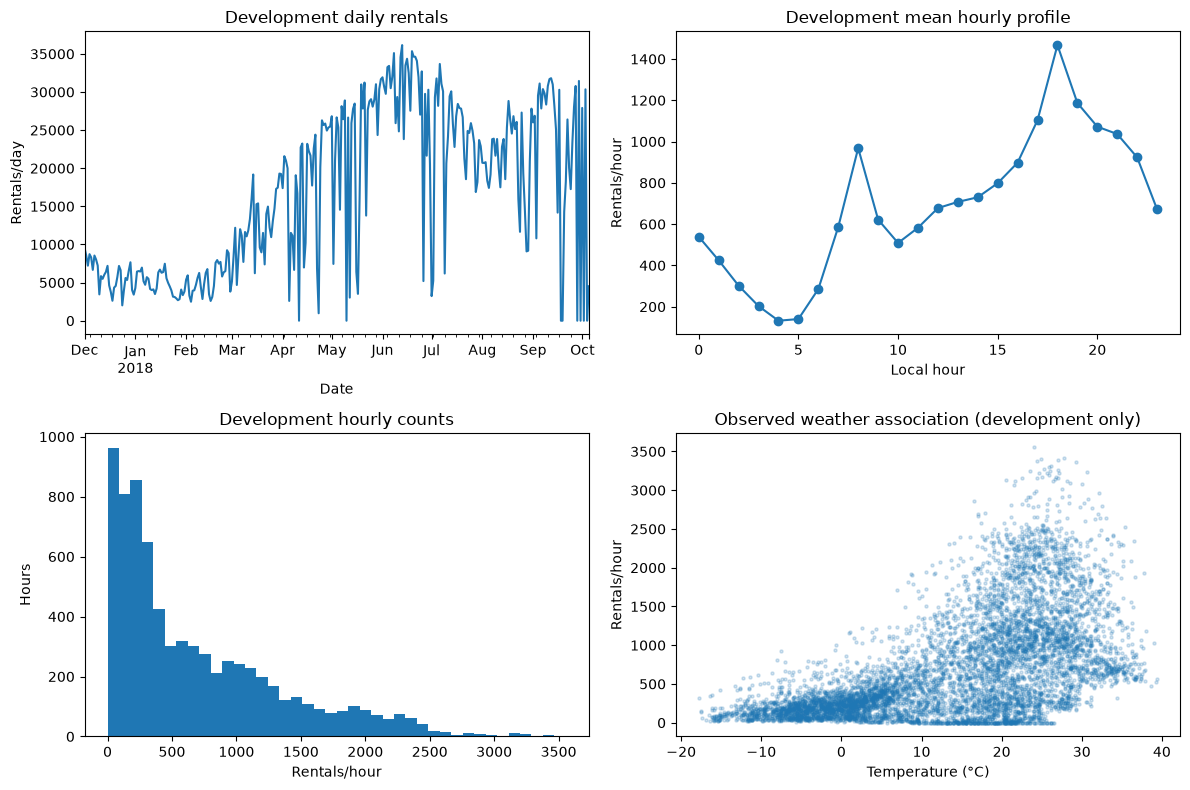

,rentals
rentals,1.000000
temperature,0.569369
dew_point,0.423200
solar,0.271052
visibility,0.194077
wind_speed,0.121419
rainfall,-0.118514
snowfall,-0.151860
humidity,-0.167787


,hours,mean_rentals,zero_hours,closed_hours
timestamp,,,,
2017-12,744,249.099462,0,0
2018-01,744,201.620968,0,0
2018-02,672,225.941964,0,0
2018-03,744,511.551075,0,0
2018-04,720,728.093056,24,24
2018-05,744,950.387097,24,24
2018-06,720,1245.676389,0,0
2018-07,744,987.177419,0,0
2018-08,744,876.192204,0,0


In [3]:
train_raw = raw[raw.timestamp < cutoff].copy()
quality = pd.DataFrame({"type": train_raw.dtypes.astype(str), "missing": train_raw.isna().sum(),
                        "distinct": train_raw.nunique()})
quality.to_csv(REPORTS / "development_data_quality.csv")
display(train_raw[["rentals", *WEATHER.values()]].describe())
print("Development zero counts:", int(train_raw.rentals.eq(0).sum()))
print("Development closed hours:", int(train_raw.functioning.eq("No").sum()))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
train_raw.set_index("timestamp").rentals.resample("D").sum().plot(ax=axes[0,0])
axes[0,0].set(title="Development daily rentals", ylabel="Rentals/day", xlabel="Date")
train_raw.groupby(train_raw.timestamp.dt.hour).rentals.mean().plot(ax=axes[0,1], marker="o")
axes[0,1].set(title="Development mean hourly profile", xlabel="Local hour", ylabel="Rentals/hour")
train_raw.rentals.plot.hist(bins=40, ax=axes[1,0])
axes[1,0].set(title="Development hourly counts", xlabel="Rentals/hour", ylabel="Hours")
axes[1,1].scatter(train_raw.temperature, train_raw.rentals, s=5, alpha=.2)
axes[1,1].set(title="Observed weather association (development only)", xlabel="Temperature (°C)", ylabel="Rentals/hour")
fig.tight_layout()
fig.savefig(REPORTS / "development_eda.png", dpi=130)
plt.show()
correlations = train_raw[["rentals", *WEATHER.values()]].corr()[["rentals"]].sort_values("rentals", ascending=False)
display(correlations)
correlations.to_csv(REPORTS / "development_correlations.csv")
lag_associations = development[["rentals", "rentals_lag24", "rentals_lag168", *[f"{c}_lag24" for c in WEATHER.values()]]].corr()[["rentals"]]
lag_associations.to_csv(REPORTS / "development_lag_associations.csv")
monthly = train_raw.groupby(train_raw.timestamp.dt.strftime("%Y-%m")).agg(
    hours=("rentals", "size"), mean_rentals=("rentals", "mean"),
    zero_hours=("rentals", lambda x: int(x.eq(0).sum())),
    closed_hours=("functioning", lambda x: int(x.eq("No").sum())))
monthly.to_csv(REPORTS / "development_monthly_summary.csv")
display(monthly)


## 3. Modify

**Select and construct.** Target: `Rented Bike Count`. Features: previous-day and
previous-week rentals at the same hour; previous-day weather at the same hour;
cyclical hour, weekday, and annual position; known holiday status. Drop raw date
strings, seasons (redundant calendar information), actual operating status, and
same-day weather. Do not use contemporaneous target counts, centered windows,
backward filling, or full-data target aggregates.

Lagging the full ordered source table is safe here because every source timestamp
strictly precedes its forecast day's midnight. A later test day may use observed
earlier test-day history; this is the declared daily-update protocol, not model
refitting or access to future outcomes. It would be invalid for a fixed multiweek
forecast or if prior-day observations were delayed.

**Clean, transform, and preserve the recipe.** The shared feature builder validates
the inference schema and creates calendar features inside the persisted pipeline.
For learned models, numeric median imputation and standardization are fitted only
on each fold's training rows. There are no missing values in the verified source;
imputation supports missing lagged weather at inference. Lag provenance and
prefix-invariance checks below prevent accidental future-dependent feature creation.
Missing or fractional historical rental counts are rejected rather than silently imputed; the
persistence baseline requires a complete previous day.

The lag builder now rejects unordered or gapped source histories instead of
silently shifting by row position. Missing lagged weather is still imputed using
training medians; this does not create a reporting-delay correction. Complete
rental history and correctly timestamped observations remain required inputs.

For the scoring example, construct the entire next-day input table from an
as-of-midnight historical extract with `make_day_inputs`. It rejects future
history or missing required lag timestamps, and reproduces the bulk lag-builder
inputs. This verifies construction with the assumed reporting availability; it
cannot validate an external feed's actual release times or a calendar's accuracy.

In [4]:
assert X_dev.notna().all().all() and X_test.notna().all().all()
# Calendar-day availability: even an hour-23 forecast uses only yesterday's hour 23.
for lag in [24, 168]:
    assert (supervised.timestamp - pd.Timedelta(hours=lag) < supervised.timestamp.dt.normalize()).all()
    source_index = pd.DatetimeIndex(supervised.timestamp - pd.Timedelta(hours=lag))
    expected = raw.set_index("timestamp").loc[source_index, "rentals"].to_numpy()
    np.testing.assert_array_equal(supervised[f"rentals_lag{lag}"], expected)
for column in WEATHER.values():
    expected = raw.set_index("timestamp").loc[pd.DatetimeIndex(supervised.timestamp-pd.Timedelta(hours=24)), column]
    np.testing.assert_array_equal(supervised[f"{column}_lag24"], expected.to_numpy())
# Truncating all future data leaves historical features exactly unchanged.
prefix_end = int(raw.index[raw.timestamp.eq(cutoff)][0])
prefix = build_supervised(raw.iloc[:prefix_end])
pd.testing.assert_frame_equal(prefix[INPUTS], development[INPUTS].reset_index(drop=True))
display(design_matrix(X_dev.head()))
print("Causal lag availability, exact source alignment, and prefix invariance verified.")

,hour_sin,hour_cos,weekday_sin,weekday_cos,year_sin,year_cos,holiday,rentals_lag24,rentals_lag168,temperature_lag24,humidity_lag24,wind_speed_lag24,visibility_lag24,dew_point_lag24,solar_lag24,rainfall_lag24,snowfall_lag24
0,0.000000,1.000000,-0.433884,-0.900969,-0.405165,0.914244,0.0,198.0,254.0,1.4,92.0,0.5,240.0,0.2,0.0,0.0,0.9
1,0.258819,0.965926,-0.433884,-0.900969,-0.405165,0.914244,0.0,218.0,204.0,1.5,92.0,0.4,227.0,0.3,0.0,0.0,0.9
2,0.500000,0.866025,-0.433884,-0.900969,-0.405165,0.914244,0.0,149.0,173.0,1.4,92.0,0.7,168.0,0.2,0.0,0.0,0.9
3,0.707107,0.707107,-0.433884,-0.900969,-0.405165,0.914244,0.0,102.0,107.0,1.9,91.0,1.4,218.0,0.5,0.0,0.0,0.9
4,0.866025,0.500000,-0.433884,-0.900969,-0.405165,0.914244,0.0,62.0,78.0,1.6,92.0,0.7,119.0,0.4,0.0,0.0,0.9


Causal lag availability, exact source alignment, and prefix invariance verified.


## 4. Model

**Choose methods and fit.** Compare previous-day persistence, Ridge regression
(alpha=10), and Poisson-loss histogram gradient boosting (180 iterations, 15 leaf
nodes, minimum leaf size 25, learning rate 0.07, L2=1). Fixed settings keep the
comparison small. Poisson loss matches nonnegative count targets without assuming
that conditional variance actually equals the mean; no inferential Poisson claims
are made. Disable boosting's internal early stopping so it cannot create a random
validation split. Clip linear predictions to zero using the same rule in validation,
test, and saved-model inference; do not round point predictions.

**Select with time-ordered validation.** Fit all candidates anew for each expanding
window. Select by lowest mean validation MAE (rental-count units), reporting RMSE,
R² and RMSLE as context. Avoid MAPE because zero counts are present. Fold variation
is descriptive, not an IID confidence interval. The model selected on development
folds is refit on all development rows once, then frozen for test evaluation.

**Selection is not acceptance.** Ridge minimizes a squared-error training loss;
we compare its clipped predictions by MAE, rather than claim its fitting objective
optimizes MAE. Keep the mean-MAE rule despite subsequent test underperformance.
The selected fitted model is an archived development-selected candidate, not a
proven operational champion. Report paired fold MAE differences against persistence;
overlapping training windows and seasonal shifts preclude treating three folds as
independent statistical replicates. A lower RMSE does not override an MAE failure.

Use MAE skill `1 - candidate MAE / persistence MAE` descriptively, with zero for
persistence. Positive development skill and two favorable folds do not guarantee
future improvement. Unequal seasonal difficulty and overlapping expanding training
sets mean that fold win counts and standard deviations are not inferential tests.
The selected Ridge artifact remains unchanged in role after its test MAE failure.

In [5]:
def learned_pipeline(estimator):
    return Pipeline([
        ("features", FunctionTransformer(design_matrix, validate=False)),
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", NonnegativeRegressor(estimator)),
    ])

candidates = {
    "previous_day": Pipeline([("features", FunctionTransformer(design_matrix, validate=False)),
                               ("model", PreviousDayRegressor())]),
    "ridge": learned_pipeline(Ridge(alpha=10)),
    "hist_poisson": learned_pipeline(HistGradientBoostingRegressor(
        loss="poisson", max_iter=180, max_leaf_nodes=15, min_samples_leaf=25,
        learning_rate=.07, l2_regularization=1, early_stopping=False, random_state=SEED)),
}
fold_results = []
for name, candidate in candidates.items():
    for fold, (fit, validation) in enumerate(folds, start=1):
        fitted = clone(candidate).fit(X_dev.iloc[fit], y_dev.iloc[fit])
        if name != "previous_day":
            fold_design = design_matrix(X_dev.iloc[fit])
            np.testing.assert_allclose(fitted.named_steps["impute"].statistics_, fold_design.median())
            np.testing.assert_allclose(fitted.named_steps["scale"].mean_, fold_design.mean(), atol=1e-12)
        prediction = fitted.predict(X_dev.iloc[validation])
        fold_results.append({"model": name, "fold": fold,
                             "train_only_preprocessing_verified": True,
                             **regression_metrics(y_dev.iloc[validation], prediction)})
fold_scores = pd.DataFrame(fold_results)
summary = fold_scores.groupby("model")[["mae", "rmse", "r2", "rmsle"]].agg(["mean", "std"])
summary.columns = ["_".join(c) for c in summary.columns]
summary["mae_skill_vs_persistence"] = 1 - summary["mae_mean"] / summary.loc["previous_day", "mae_mean"]
summary = summary.sort_values("mae_mean")
display(summary.round(3))
fold_scores.to_csv(REPORTS / "validation_folds.csv", index=False)
summary.to_csv(REPORTS / "model_comparison.csv")
selected_name = summary.index[0]
model = clone(candidates[selected_name]).fit(X_dev, y_dev)
print("Selected by development MAE:", selected_name)
paired_folds = fold_scores.pivot(index="fold", columns="model", values="mae")
paired_folds["ridge_minus_previous_day"] = paired_folds["ridge"] - paired_folds["previous_day"]
paired_folds.to_csv(REPORTS / "paired_validation_mae.csv")
display(paired_folds)

for name in candidates:
    paired_folds[f"{name}_mae_skill"] = 1 - paired_folds[name] / paired_folds["previous_day"]
paired_folds.to_csv(REPORTS / "paired_validation_mae.csv")


,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std,rmsle_mean,rmsle_std,mae_skill_vs_persistence
model,,,,,,,,,
ridge,332.630,164.724,471.312,221.013,0.471,0.312,1.411,1.534,0.045
previous_day,348.145,207.330,551.486,303.380,0.263,0.534,1.761,1.982,0.000
hist_poisson,379.462,171.190,518.845,210.611,0.369,0.306,1.441,1.503,-0.090


Selected by development MAE: ridge


model,hist_poisson,previous_day,ridge,ridge_minus_previous_day
fold,,,,
1,212.426086,143.120536,170.345681,27.225145
2,371.436464,343.607143,327.854955,-15.752188
3,554.523334,557.706845,499.690290,-58.016555


## 5. Assess

**Generalization and usefulness.** Evaluate the frozen selected model and the
persistence baseline on the chronological 56-day test set. Report MAE/RMSE in
rentals/hour, R², and RMSLE; inspect temporal errors and actual-vs-predicted plots.
Break down errors by month and observed open/closed status for diagnosis only.
The latter is not a predictor. No thresholds, parameters, or features are revised
using test performance. The last season is not a year-round benchmark.

**Reliability and practical interpretation.** Compare daily errors with persistence.
Use a paired seven-day block bootstrap for a descriptive 95% interval on the mean
MAE difference (selected minus baseline). This preserves within-week structure,
but only eight test weeks are available; it does not address model-selection
uncertainty or future distribution change. A negative difference favors the model.
No business-approved service target or fleet-allocation cost function is available.
Save the full fitted pipeline and demonstrate reload inference on saved examples.
A successful retrospective forecast does not prove that bicycle availability or
customer waiting times improve.

R² is omitted for slices with a constant target (such as zero-rental closed
hours), where explained-variance comparison is undefined.

Report both candidate and persistence errors on exactly the same error slices,
including hour counts. Positive MAE differences favor persistence. This is
post-selection diagnosis, not permission to switch the archived model using the
known test outcome. Failure to establish superiority is not evidence of equality
or non-inferiority. The release decision remains separate from metric computation.

The interval is an **exploratory percentile resampling summary**, conditional on
this fitted candidate and eight observed weekly blocks. Resampling these weeks
assumes they are exchangeable and does not preserve dependence between weeks or
remove seasonal drift. Its nominal 95% label is not a coverage guarantee. Including
zero does not establish equal performance, non-inferiority, or acceptable business
loss. The primary observed difference is positive (worse), and RMSE improvement
cannot overturn that assessment. The test period has been repeatedly inspected.

{
  "selected_model": "ridge",
  "seed": 42,
  "test_role": "reused chronological benchmark; not independent confirmation",
  "development_rows": 7248,
  "test_rows": 1344,
  "development_start": "2017-12-08 00:00:00",
  "development_end": "2018-10-05 23:00:00",
  "test_start": "2018-10-06 00:00:00",
  "test_end": "2018-11-30 23:00:00",
  "selected": {
    "mae": 330.7551292799832,
    "rmse": 439.14604315254144,
    "r2": 0.4133936043708636,
    "rmsle": 2.0404586392982504
  },
  "previous_day": {
    "mae": 301.3668154761905,
    "rmse": 516.9601530593925,
    "r2": 0.1870890300416832,
    "rmsle": 2.608201710949565
  },
  "mae_difference": 29.388313803792673,
  "paired_week_block_95_interval": {
    "lower": -42.73739040159208,
    "upper": 98.29910015270785
  },
  "mae_reduction_percent": -9.75167546478406
}


,field,value,hours,mae,rmse,r2,rmsle,baseline_mae,baseline_rmse,baseline_r2,baseline_rmsle,mae_difference,weighted_mae_difference_contribution,mean_signed_error,baseline_mean_signed_error
0,month,2018-10,624,332.940614,443.781153,0.497972,1.529261,322.341346,549.604472,0.230000,2.283658,10.599268,4.921089,-206.451988,-27.280449
1,month,2018-11,720,328.861043,435.089007,0.188230,2.396872,283.188889,486.901251,-0.016620,2.859835,45.672154,24.467225,-142.924105,7.288889
2,functioning,No,103,596.229547,691.861283,NaN,6.186831,797.660194,1043.172509,NaN,6.184086,-201.430647,-15.437021,596.229547,797.660194
3,functioning,Yes,1241,308.721394,411.250102,0.437744,1.154184,260.175665,446.217452,0.338065,2.047744,48.545730,44.825335,-236.215181,-75.692184


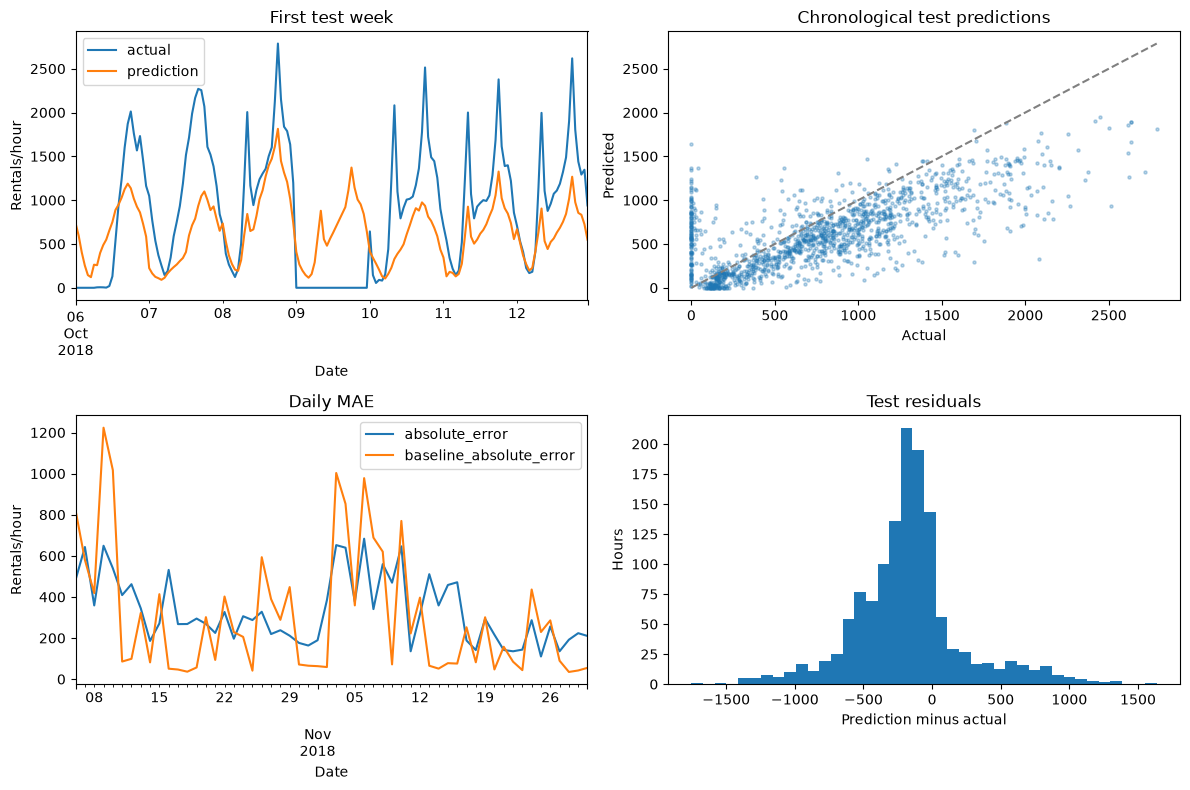

803

In [6]:
prediction = model.predict(X_test)
baseline = clone(candidates["previous_day"]).fit(X_dev, y_dev).predict(X_test)
metrics = {
    "selected_model": selected_name, "seed": SEED,
    "test_role": "reused chronological benchmark; not independent confirmation",
    "development_rows": len(development), "test_rows": len(test),
    "development_start": str(development.timestamp.min()), "development_end": str(development.timestamp.max()),
    "test_start": str(test.timestamp.min()), "test_end": str(test.timestamp.max()),
    "selected": regression_metrics(y_test, prediction),
    "previous_day": regression_metrics(y_test, baseline),
}
results = pd.DataFrame({"timestamp": test.timestamp.to_numpy(), "actual": y_test.to_numpy(),
                        "prediction": prediction, "previous_day": baseline,
                        "functioning": test.functioning.to_numpy()})
results["absolute_error"] = np.abs(results.actual - results.prediction)
results["baseline_absolute_error"] = np.abs(results.actual - results.previous_day)
results.to_csv(OUTPUTS / "test_predictions.csv", index=False)
daily = results.set_index("timestamp")[["absolute_error", "baseline_absolute_error"]].resample("D").mean()
daily.to_csv(REPORTS / "daily_errors.csv")
weekly_differences = (daily.absolute_error-daily.baseline_absolute_error).to_numpy().reshape(8,7).mean(axis=1)
rng = np.random.default_rng(SEED)
boot = rng.choice(weekly_differences, size=(1000, 8), replace=True).mean(axis=1)
metrics["mae_difference"] = float((daily.absolute_error-daily.baseline_absolute_error).mean())
metrics["paired_week_block_95_interval"] = dict(zip(["lower", "upper"], np.quantile(boot, [.025,.975]).tolist()))
metrics["mae_reduction_percent"] = float(100*(1-metrics["selected"]["mae"]/metrics["previous_day"]["mae"]))
print(json.dumps(metrics, indent=2))
slices = []
for field, values in [("month", results.timestamp.dt.strftime("%Y-%m")), ("functioning", results.functioning)]:
    for value in sorted(values.unique()):
        mask = values.eq(value)
        slices.append({"field": field, "value": value, "hours": int(mask.sum()),
                       **regression_metrics(results.loc[mask,"actual"], results.loc[mask,"prediction"]),
                       **{f"baseline_{key}": value for key,value in regression_metrics(results.loc[mask,"actual"], results.loc[mask,"previous_day"]).items()},
                       "mae_difference": float((results.loc[mask,"absolute_error"]-results.loc[mask,"baseline_absolute_error"]).mean())})
slice_metrics = pd.DataFrame(slices)
slice_metrics["weighted_mae_difference_contribution"] = slice_metrics["hours"] / len(test) * slice_metrics["mae_difference"]
for row_index, row in slice_metrics.iterrows():
    labels = results.timestamp.dt.strftime("%Y-%m") if row["field"] == "month" else results.functioning
    mask = labels.eq(row["value"])
    slice_metrics.loc[row_index, "mean_signed_error"] = float((results.loc[mask,"prediction"]-results.loc[mask,"actual"]).mean())
    slice_metrics.loc[row_index, "baseline_mean_signed_error"] = float((results.loc[mask,"previous_day"]-results.loc[mask,"actual"]).mean())
for _, group in slice_metrics.groupby("field"):
    assert group.hours.sum() == len(test)
    np.testing.assert_allclose(group.weighted_mae_difference_contribution.sum(),metrics["mae_difference"])
display(slice_metrics)
slice_metrics.to_csv(REPORTS / "error_slices.csv", index=False)
fig, axes = plt.subplots(2, 2, figsize=(12,8))
results.head(168).set_index("timestamp")[["actual", "prediction"]].plot(ax=axes[0,0])
axes[0,0].set(title="First test week", ylabel="Rentals/hour", xlabel="Date")
axes[0,1].scatter(results.actual, results.prediction, s=5, alpha=.3)
limit = max(results.actual.max(), results.prediction.max())
axes[0,1].plot([0,limit], [0,limit], "--", color="gray")
axes[0,1].set(title="Chronological test predictions", xlabel="Actual", ylabel="Predicted")
daily.plot(ax=axes[1,0])
axes[1,0].set(title="Daily MAE", ylabel="Rentals/hour", xlabel="Date")
(results.prediction-results.actual).plot.hist(bins=40, ax=axes[1,1])
axes[1,1].set(title="Test residuals", xlabel="Prediction minus actual", ylabel="Hours")
fig.tight_layout()
fig.savefig(REPORTS / "test_evaluation.png", dpi=130)
plt.show()
(REPORTS / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
decision = {
    "development_selected_candidate": selected_name,
    "selection_rule": "minimum mean expanding-window validation MAE",
    "test_primary_metric_improved": bool(metrics["selected"]["mae"] < metrics["previous_day"]["mae"]),
    "ridge_promotion_supported": False,
    "validation_ridge_mae_skill": float(summary.loc["ridge", "mae_skill_vs_persistence"]),
    "ridge_validation_folds_with_lower_mae": int(paired_folds["ridge_minus_previous_day"].lt(0).sum()),
    "uncertainty_interpretation": "exploratory eight-week resampling; no equivalence or non-inferiority claim",
    "test_role": "reused benchmark after review",
    "conclusion": "Ridge does not improve observed primary test MAE; no demonstrated superiority or non-inferiority",
    "artifact_role": "archived development-selected candidate for reproducible study, not operational recommendation",
    "next_step": "Keep persistence as reference; obtain new dated evidence and decision costs before changing policy",
}
(REPORTS / "assessment.json").write_text(json.dumps(decision, indent=2) + "\n")


### Prediction demonstration and reproducible handoff

The saved pipeline expects a timestamp, known holiday label, two historical rental
counts, and eight previous-day weather measurements. It validates inputs and
reconstructs calendar features consistently. The provided example profiles are
complete inputs from five evaluated hours, not unseen prospective customers.
Only load trusted joblib artifacts; keep `src/seoul.py` available for its serialized
functions/classes. The input contract records when each field is available.

Dataset and source/model hashes, split boundaries, parameters, exact direct package
versions, metrics, and plots support replay. Raw data is excluded from Git and can
be downloaded again from the versioned source; final outputs are allowlisted.
The requirements file pins direct dependencies, not every transitive dependency.

In [7]:
model_path = OUTPUTS / "demand_pipeline.joblib"
joblib.dump(model, model_path)
loaded = joblib.load(model_path)
np.testing.assert_allclose(loaded.predict(X_test), prediction, rtol=0, atol=0)
origin = test.timestamp.iloc[0].normalize()
known_holiday = X_test.holiday.iloc[0]  # Fixture for the assumed known future calendar.
as_of_history = raw[raw.timestamp < origin].copy()
day_inputs = make_day_inputs(as_of_history, origin, known_holiday)
pd.testing.assert_frame_equal(day_inputs, X_test.head(24).reset_index(drop=True), check_dtype=False)
np.testing.assert_allclose(loaded.predict(day_inputs), prediction[:24], rtol=0, atol=0)
examples = day_inputs.head(5)
examples.to_csv(OUTPUTS / "example_profiles.csv", index=False)
demo = pd.DataFrame({"timestamp": examples.timestamp.to_numpy(), "predicted_rentals": loaded.predict(examples)})
demo.to_csv(REPORTS / "prediction_demo.csv", index=False)
display(demo)
notebook_path = PROJECT / "notebooks/seoul_bike_semma.ipynb"
source = json.loads(notebook_path.read_text())
code_source = "\n\n".join(c["source"] if isinstance(c["source"],str) else "".join(c["source"])
                          for c in source["cells"] if c["cell_type"] == "code")
packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib", "nbformat", "nbclient", "ipykernel", "jupyterlab"]
manifest = {
    "dataset": DATASET, "dataset_version": 1, "source_url": SOURCE_URL, "download_url": DOWNLOAD_URL,
    "dataset_sha256": SHA256, "encoding": "latin1", "python": platform.python_version(),
    "packages": {p:version(p) for p in packages}, "seed": SEED,
    "protocol": "rolling daily forecasts at midnight; previous days fully observed; fixed fitted model",
    "model": selected_name, "parameters": {key:value for key,value in model.get_params(deep=True).items() if isinstance(value, (str, int, float, bool)) or value is None},
    "split": {key:metrics[key] for key in ["development_start", "development_end", "test_start", "test_end"]},
    "cv": {"folds": 3, "validation_days": 28, "gap_hours": 24, "final_fit_gap_hours": 0},
    "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
    "source_sha256": hashlib.sha256((PROJECT / "src/seoul.py").read_bytes()).hexdigest(),
    "notebook_code_sha256": hashlib.sha256(code_source.encode()).hexdigest(),
    "bootstrap": {"replicates":1000, "block_days":7, "test_blocks":8, "seed":SEED},
}
(OUTPUTS / "run_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
(PROJECT / "requirements.txt").write_text("# Python 3.11; verified direct versions, not a transitive lockfile.\n" +
                                       "".join(f"{p}=={version(p)}\n" for p in packages))
contract = {"columns": INPUTS, "calendar": "timestamp and holiday known before forecast day",
            "historical_inputs": "rentals_lag24, rentals_lag168 and each *_lag24 weather value refer to that timestamp minus the stated hours",
            "availability_assumption": "prior day complete at local midnight, no reporting delay",
            "never_inputs": ["same-day rentals", "same-day measured weather", "actual Functioning Day"],
            "missingness": "rental lags must be observed nonnegative integers; learned models median-impute missing weather lags only"}
(REPORTS / "input_contract.json").write_text(json.dumps(contract, indent=2) + "\n")
print("All test predictions reproduced exactly after model reload.")
print(f"Selected {selected_name}; test MAE {metrics['selected']['mae']:.2f}, RMSE {metrics['selected']['rmse']:.2f}, R² {metrics['selected']['r2']:.3f}.")
print(f"MAE difference (selected minus persistence): {metrics['mae_difference']:+.2f} rentals/hour; positive is worse.")
print("Primary metric:", "beats baseline" if metrics["mae_difference"] < 0 else "does not beat baseline")

,timestamp,predicted_rentals
0,2018-10-06 00:00:00,735.335929
1,2018-10-06 01:00:00,594.620871
2,2018-10-06 02:00:00,404.689922
3,2018-10-06 03:00:00,254.634038
4,2018-10-06 04:00:00,144.538681


All test predictions reproduced exactly after model reload.
Selected ridge; test MAE 330.76, RMSE 439.15, R² 0.413.
MAE difference (selected minus persistence): +29.39 rentals/hour; positive is worse.
Primary metric: does not beat baseline


### Limitations and next steps

One year from one city offers limited seasonal replication, and the test block
covers only the last 56 days. Serial dependence and eight weekly bootstrap blocks
limit uncertainty claims. Actual operating closures and sudden weather changes
cannot be known from yesterday's measurements; closed-hour errors should remain
visible rather than be removed after evaluation. Holiday status is assumed known.
Lag inputs must be constructed from correctly aligned, timely observations; input
schema validation alone cannot establish their provenance in a live service.
Use additional dated years and genuinely available forecasts/operating schedules
for prospective evaluation. Do not change model settings based on this test set
without a new independent test period. There is no approved service-cost target,
real-time feed, prediction service, or verified fleet-management benefit.

On this test period the validation-selected Ridge model does **not** improve MAE
over previous-day persistence, although RMSE improves. The paired weekly-block
interval includes zero; there is no robust superiority claim. Closed hours are difficult for both methods, but Ridge improves MAE there.
Its operating-hour losses dominate that gain and explain the relative shortfall. Model settings and selection remain unchanged after
seeing these results.

The saved Ridge candidate is retained to reproduce the original selection rule,
not promoted as better than persistence. Subsequent decisions need new dated
validation/test evidence; the repeatedly inspected block cannot support fresh
confirmatory claims.